# Fine-tuning YOLO11x-OBB — (2) **Encoder saja**

Hanya **encoder = backbone YOLO11 (layer 0–10)** yang dilatih. Neck (layer 11–22) dan head OBB dibekukan.
Hyperparameter **identik** dengan notebook (1) agar perbandingan adil.

| Hyperparameter | Nilai |
|---|---|
| Optimizer | SGD + momentum Nesterov |
| Learning rate awal (`lr0`) | 0,01 |
| Learning rate akhir (`lrf`) | 0,2 × lr0 = 0,002 |
| Scheduler | Linear decay (`cos_lr=False`) |
| Weight decay | 0,0005 |
| Warmup | 3 epoch |
| Batch size | 2 |
| Epochs | 30 |

**Cara pembekuan:** callback `on_train_start` (dan `on_train_epoch_start`) mengatur `requires_grad=False` untuk layer ≥ 11, dan callback `on_train_batch_start` menjaga BatchNorm bagian beku tetap mode eval agar *running statistics*-nya ikut beku (pembekuan bawaan Ultralytics tidak melakukan ini).

**Penting — lapisan kelas baru:** karena jumlah kelas berubah (15 → 1), 3 conv 1×1 prediksi kelas pada head diinisialisasi acak. Secara default (`TRAIN_NEW_CLS_LAYER=True`) hanya lapisan kecil ini yang ikut dilatih; selain itu seluruh neck/head beku. Set `False` untuk versi yang benar-benar encoder-only (hasil kemungkinan jauh lebih buruk karena prediktor kelas tetap acak).

Catatan `nbs=64` dan syarat sesi sama seperti notebook (1).

In [1]:
# Ultralytics (di Kaggle biasanya sudah ada; sel ini hanya memastikan)
import importlib, subprocess, sys
try:
    importlib.import_module("ultralytics")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

import os, re, json
from pathlib import Path
os.environ["WANDB_DISABLED"] = "true"          # matikan logger eksternal

import yaml, torch
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__, "| torch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (aktifkan GPU di Kaggle: Settings > Accelerator)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.218 | torch: 2.11.0+cu130
GPU: Tesla T4


In [2]:
!pip install -q shapely lxml tqdm huggingface_hub

In [3]:
HF_REPO_ID = "WARAJA/Tzefa-Line-Segmentation-YOLO"
HF_FILENAME = "best.pt"
WORK_DIR = "/kaggle/working"

In [4]:
from huggingface_hub import hf_hub_download

# ------------------------------ KONFIGURASI ------------------------------
MODEL_WEIGHTS = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_FILENAME, local_dir=f"{WORK_DIR}/yolov11-obb-base")    # bobot pretrained (diunduh otomatis; butuh Internet ON di Kaggle)
RUN_NAME      = "ft_encoder_only"
PROJECT       = "/kaggle/working/runs"
DATA_YAML_SRC = None                 # None = cari otomatis data.yaml hasil konversi; atau isi path manual
IMGSZ         = 640                 # baris tulisan tipis & panjang -> resolusi tinggi membantu
DEVICE        = 0 if torch.cuda.is_available() else "cpu"   # 1 GPU; hindari DDP agar callback freeze aman
WORKERS       = 2

# Konfigurasi FINE-TUNING (titik awal sudah terlatih untuk baris tulisan -> langkah belajar halus, augmentasi ringan)
TRAIN_ARGS = dict(
    epochs=30,
    batch=4,
    nbs=16,                   # batch efektif 16 -> ±4 iterasi per update (lihat sel estimasi update)
    optimizer="SGD",          # Ultralytics memakai SGD(momentum, nesterov=True) -> Nesterov aktif
    momentum=0.937,
    lr0=0.002,                # lebih kecil dari default 0.01: jangan merusak fitur yang sudah terlatih
    lrf=0.1,                  # lr akhir = lr0 * lrf = 0.0002
    cos_lr=False,             # False = linear decay
    weight_decay=0.0005,
    warmup_epochs=1,
    warmup_bias_lr=0.01,      # default 0.1 terlalu agresif untuk bobot terlatih
    warmup_momentum=0.8,
    imgsz=IMGSZ,
    device=DEVICE,
    workers=WORKERS,
    patience=30,              # = epochs -> tanpa early stopping
    seed=42, deterministic=True,
    # Augmentasi ringan: halaman manuskrip punya tata letak tetap (baris horizontal, sedikit miring)
    mosaic=0.0, mixup=0.0,    # mosaic memotong-tempel halaman -> merusak konteks tata letak
    degrees=2.0, translate=0.05, scale=0.25, shear=0.0, perspective=0.0,
    hsv_h=0.01, hsv_s=0.4, hsv_v=0.3,
    fliplr=0.0, flipud=0.0,   # jangan membalik arah baca dokumen
    plots=True, save_period=5,
    project=PROJECT, name=RUN_NAME, exist_ok=False,
)

for k, v in TRAIN_ARGS.items():
    print(f"{k:>14}: {v}")

best.pt: reconstructing file:   0%|          |  0.00B /  118MB            

best.pt: downloading bytes:           |  0.00B            

        epochs: 30
         batch: 4
           nbs: 16
     optimizer: SGD
      momentum: 0.937
           lr0: 0.002
           lrf: 0.1
        cos_lr: False
  weight_decay: 0.0005
 warmup_epochs: 1
warmup_bias_lr: 0.01
warmup_momentum: 0.8
         imgsz: 640
        device: 0
       workers: 2
      patience: 30
          seed: 42
 deterministic: True
        mosaic: 0.0
         mixup: 0.0
       degrees: 2.0
     translate: 0.05
         scale: 0.25
         shear: 0.0
   perspective: 0.0
         hsv_h: 0.01
         hsv_s: 0.4
         hsv_v: 0.3
        fliplr: 0.0
        flipud: 0.0
         plots: True
   save_period: 5
       project: /kaggle/working/runs
          name: ft_encoder_only
      exist_ok: False


In [5]:
# Laporan parameter per bagian arsitektur YOLO11-OBB:
#   backbone/encoder = layer 0-10 | neck = layer 11-22 | head OBB = layer terakhir (23)
BACKBONE_END = 10

def layer_idx(name):
    m = re.match(r"model\.(\d+)\.", name)
    return int(m.group(1)) if m else None

def param_report(trainer):
    net = trainer.model
    head_idx = len(net.model) - 1
    groups = {"backbone (0-10)": [0, 0], "neck (11-22)": [0, 0], f"head OBB ({head_idx})": [0, 0]}
    for n, p in net.named_parameters():
        i = layer_idx(n)
        g = "backbone (0-10)" if i <= BACKBONE_END else ("neck (11-22)" if i < head_idx else f"head OBB ({head_idx})")
        groups[g][0] += p.numel()
        groups[g][1] += p.numel() if p.requires_grad else 0
    print(f"{'bagian':<18}{'total':>14}{'trainable':>14}{'%':>8}")
    for g, (tot, tr) in groups.items():
        print(f"{g:<18}{tot:>14,}{tr:>14,}{100*tr/max(tot,1):>8.1f}")
    T = sum(v[0] for v in groups.values()); R = sum(v[1] for v in groups.values())
    print(f"{'TOTAL':<18}{T:>14,}{R:>14,}{100*R/T:>8.1f}")

In [6]:
def find_data_yaml():
    """Cari data.yaml hasil konversi (di /kaggle/working atau dataset yang di-attach sebagai input)."""
    for base in (Path("/kaggle/working"), Path("/kaggle/input")):
        if base.exists():
            for p in sorted(base.rglob("data.yaml")):
                if (p.parent / "images").is_dir() and (p.parent / "labels").is_dir():
                    return p
    return None

src = Path(DATA_YAML_SRC) if DATA_YAML_SRC else find_data_yaml()
assert src is not None and src.exists(), "data.yaml tidak ditemukan. Set DATA_YAML_SRC secara manual."

# Tulis ulang data.yaml dengan 'path' absolut yang benar untuk sesi ini (input Kaggle itu read-only,
# sehingga YAML runtime ditulis ke /kaggle/working).
cfg = yaml.safe_load(src.read_text())
cfg["path"] = str(src.parent.resolve())
for s in ("train", "val", "test"):
    d = src.parent / "images" / s
    if s in cfg and not (d.is_dir() and any(d.iterdir())):
        cfg.pop(s)                                   # buang split yang kosong
DATA_YAML = Path("/kaggle/working/data_runtime.yaml")
DATA_YAML.write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())

for s in ("train", "val", "test"):
    im, lb = src.parent / "images" / s, src.parent / "labels" / s
    if im.is_dir():
        print(f"{s:>5}: {sum(1 for _ in im.iterdir())} gambar, {len(list(lb.glob('*.txt')))} label")

path: /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2
train: images/train
val: images/val
test: images/test
names:
  0: line

train: 206 gambar, 206 label
  val: 25 gambar, 25 label
 test: 27 gambar, 27 label


In [7]:
# ----------------------------------------------------------------------------------
# ENCODER-ONLY: hanya backbone (layer 0-10: Conv, C3k2, SPPF, C2PSA) yang dilatih.
# Neck (11-22) dan head OBB dibekukan.
#
# Pengecualian yang diperlukan: kelas berubah 15 -> 1, sehingga lapisan prediksi kelas (cv3.*.2) pada head
# diinisialisasi ulang secara acak. Jika ikut dibekukan, ia tetap acak & model tidak bisa belajar benar.
# TRAIN_NEW_CLS_LAYER=True melatih HANYA 3 conv 1x1 itu; set False untuk encoder-only yang benar-benar ketat.
# ----------------------------------------------------------------------------------
TRAIN_NEW_CLS_LAYER = True
FREEZE_BN_STATS     = True     # BatchNorm di bagian beku tetap mode eval -> running stats ikut beku
NEW_CLS = re.compile(r"^model\.\d+\.cv3\.\d+\.2\.")     # conv 1x1 prediksi kelas di head

_frozen_bn = []

def apply_encoder_only(trainer):
    net = trainer.model
    head_idx = len(net.model) - 1
    assert type(net.model[head_idx]).__name__ == "OBB", "layer terakhir bukan head OBB; indeks layer perlu disesuaikan"
    for n, p in net.named_parameters():
        i = layer_idx(n)
        train = i <= BACKBONE_END
        if i == head_idx and TRAIN_NEW_CLS_LAYER and NEW_CLS.match(n):
            train = True
        p.requires_grad = train
    # Kumpulkan BatchNorm milik bagian beku (JANGAN meng-eval-kan modul Detect/OBB: flag training dipakai untuk loss)
    _frozen_bn.clear()
    for i, layer in enumerate(net.model):
        if i > BACKBONE_END:
            _frozen_bn.extend(m for m in layer.modules() if isinstance(m, torch.nn.modules.batchnorm._BatchNorm))

def keep_frozen_bn_eval(trainer):
    if FREEZE_BN_STATS:
        for m in _frozen_bn:
            m.eval()

## Training

In [8]:
model = YOLO(MODEL_WEIGHTS)
# Urutan penting: bekukan dulu, baru laporkan
model.add_callback("on_train_start", apply_encoder_only)
model.add_callback("on_train_epoch_start", apply_encoder_only)   # idempoten; jaga-jaga jika ada reset requires_grad
model.add_callback("on_train_start", param_report)
model.add_callback("on_train_batch_start", keep_frozen_bn_eval)

results = model.train(data=str(DATA_YAML), **TRAIN_ARGS)
SAVE_DIR = Path(model.trainer.save_dir)
print("Hasil tersimpan di:", SAVE_DIR)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_runtime.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolov11-obb-base/best.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=ft_encoder_only, nbs=16, n

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      4.57G      1.379     0.8697      3.291   0.001781         46        640: 100% ━━━━━━━━━━━━ 52/52 3.9it/s 13.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 8.7it/s 0.8s
                   all         25        488      0.777      0.668      0.783      0.379

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss angle_loss  Instances       Size
       3/30      4.57G       1.41     0.8313      2.264   0.002212         38        640: 100% ━━━━━━━━━━━━ 52/52 3.8it/s 13.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 8.9it/s 0.8s
                   all         25        488      0.975      0.978      0.992      0.643

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss angle_loss  Instances       Size
       4/30      4.57G      1.294     0.7289      2.435   0.001801         39        640: 100% ━━━━━━━━━━━━ 52/52 3.8it/s 13.8s
        

## Verifikasi jadwal LR & kurva validasi

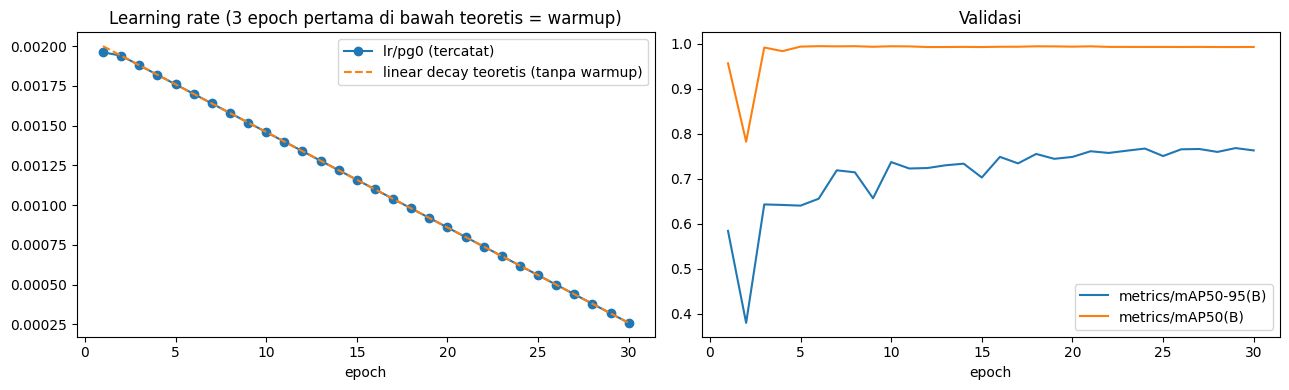

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,train/angle_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,val/angle_loss,lr/pg0,lr/pg1,lr/pg2
25,26,413.086,1.00752,0.48443,1.13035,0.00125,0.99795,0.99790,0.99318,0.76558,0.83177,0.44347,1.04380,0.00054,0.00050,0.00050,0.00050
26,27,428.761,0.98017,0.47866,1.10492,0.00117,0.99773,0.99795,0.99334,0.76624,0.83517,0.43827,1.02496,0.00058,0.00044,0.00044,0.00044
27,28,444.444,0.94628,0.47205,1.08480,0.00106,0.99782,0.99795,0.99311,0.75976,0.85320,0.43711,1.00829,0.00066,0.00038,0.00038,0.00038
28,29,460.520,0.95280,0.47024,1.12967,0.00109,0.99592,1.00000,0.99307,0.76830,0.82284,0.43811,1.03031,0.00052,0.00032,0.00032,0.00032
29,30,476.306,0.98118,0.48022,1.10616,0.00117,0.99592,0.99995,0.99324,0.76306,0.84411,0.43554,1.01512,0.00061,0.00026,0.00026,0.00026


In [9]:
# Verifikasi jadwal learning rate & kurva metrik dari results.csv
res = pd.read_csv(SAVE_DIR / "results.csv"); res.columns = [c.strip() for c in res.columns]
E, lr0, lrf = TRAIN_ARGS["epochs"], TRAIN_ARGS["lr0"], TRAIN_ARGS["lrf"]
expected = [lr0 * ((1 - e / E) * (1 - lrf) + lrf) for e in range(len(res))]    # linear decay lr0 -> lr0*lrf

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(res["epoch"], res["lr/pg0"], "o-", label="lr/pg0 (tercatat)")
ax[0].plot(res["epoch"], expected, "--", label="linear decay teoretis (tanpa warmup)")
ax[0].set_title("Learning rate (3 epoch pertama di bawah teoretis = warmup)"); ax[0].set_xlabel("epoch"); ax[0].legend()
m_cols = [c for c in res.columns if "mAP50-95" in c] + [c for c in res.columns if c.endswith("mAP50(B)")]
for c in m_cols: ax[1].plot(res["epoch"], res[c], label=c)
ax[1].set_title("Validasi"); ax[1].set_xlabel("epoch"); ax[1].legend(); plt.tight_layout(); plt.show()
display(res.tail(5))

## Evaluasi bobot terbaik

In [10]:
# Evaluasi bobot terbaik pada split val dan test (jika ada)
best_path = SAVE_DIR / "weights" / "best.pt"
best = YOLO(str(best_path))
summary = {}
for split in [s for s in ("val", "test") if s in cfg]:
    m = best.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=2, device=DEVICE,
                 plots=True, name=f"{RUN_NAME}_eval_{split}", exist_ok=True, project=PROJECT)
    summary[split] = {k: round(float(v), 4) for k, v in m.results_dict.items()}
display(pd.DataFrame(summary))
Path(f"/kaggle/working/{RUN_NAME}_metrics.json").write_text(json.dumps(summary, indent=2))
print("Bobot terbaik:", best_path)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11x-obb summary (fused): 199 layers, 58,736,758 parameters, 0 gradients, 203.1 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 1593.5±808.3 MB/s, size: 1786.8 KB)
val: Scanning /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2/labels/val... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 78.6it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.4it/s 3.0s
                   all         25        488      0.996          1      0.993      0.768
Speed: 1.3ms preprocess, 89.5ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /kaggle/working/runs/ft_encoder_only_eval_val
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+

,val,test
metrics/precision(B),0.9956,0.9992
metrics/recall(B),1.0000,1.0000
metrics/mAP50(B),0.9931,0.9950
metrics/mAP50-95(B),0.7676,0.7784
fitness,0.7676,0.7784


Bobot terbaik: /kaggle/working/runs/ft_encoder_only/weights/best.pt


## Verifikasi pembekuan (bobot vs pretrained)

In [11]:
# Verifikasi: bobot neck & head (kecuali lapisan kelas baru) HARUS identik dengan pretrained; backbone HARUS berubah.
def load_sd(path):
    return {k: v.detach().float().cpu() for k, v in YOLO(str(path)).model.state_dict().items()}

sd_pre, sd_new = load_sd(MODEL_WEIGHTS), load_sd(best_path)
head_idx = max(layer_idx(k) for k in sd_new if layer_idx(k) is not None)
diff = {"backbone (0-10)": 0.0, "neck (11-22)": 0.0, f"head OBB ({head_idx})": 0.0}
skipped = []
for k, v in sd_new.items():
    if k not in sd_pre or sd_pre[k].shape != v.shape:
        skipped.append(k); continue                       # lapisan kelas baru (bentuk berbeda)
    i = layer_idx(k)
    g = "backbone (0-10)" if i <= BACKBONE_END else ("neck (11-22)" if i < head_idx else f"head OBB ({head_idx})")
    diff[g] = max(diff[g], float((v - sd_pre[k]).abs().max()))
print("Selisih maksimum |bobot_baru - bobot_pretrained| per bagian:")
for g, d in diff.items(): print(f"  {g:<18} {d:.6f}")
print("Parameter dengan bentuk berbeda (diinisialisasi ulang):", len(skipped))
assert diff["neck (11-22)"] < 1e-3, "neck berubah -> pembekuan tidak bekerja!"
assert diff["backbone (0-10)"] > 0, "backbone tidak berubah -> tidak ada training pada encoder!"
print("OK: neck beku, backbone terlatih.")

Selisih maksimum |bobot_baru - bobot_pretrained| per bagian:
  backbone (0-10)    436.500000
  neck (11-22)       0.000000
  head OBB (23)      0.188049
Parameter dengan bentuk berbeda (diinisialisasi ulang): 0
OK: neck beku, backbone terlatih.
